# 02 – Análise exploratória da série diária de casos (Curitiba)

**Entrada:** `data/raw/casos_covid_parana_raw.csv` (microdados SESA/PR)  
**Saídas:**
- `data/intermediate/casos_diarios_curitiba.csv`: casos por dia (por `DATA_DIAGNOSTICO`)
- `results/figures/figura2_casos_diarios_brutos.png`: **Figura 2** do TCC
- `results/figures/figura3_serie_original_vs_mm7.png`: **Figura 3** do TCC
- `archive/componentes_stl_curitiba.csv`: decomposição STL (exploratória, fora do TCC)

A média móvel de 7 dias (MM7) é usada **apenas para visualização**. Os testes estatísticos usam a série agregada por semana (notebook 02b).

C:\Users\Henrique\AppData\Local\Temp\ipykernel_19680\1727301665.py:8: DtypeWarning: Columns (12,13,15) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(caminho_arquivo, sep=';', encoding='latin1')


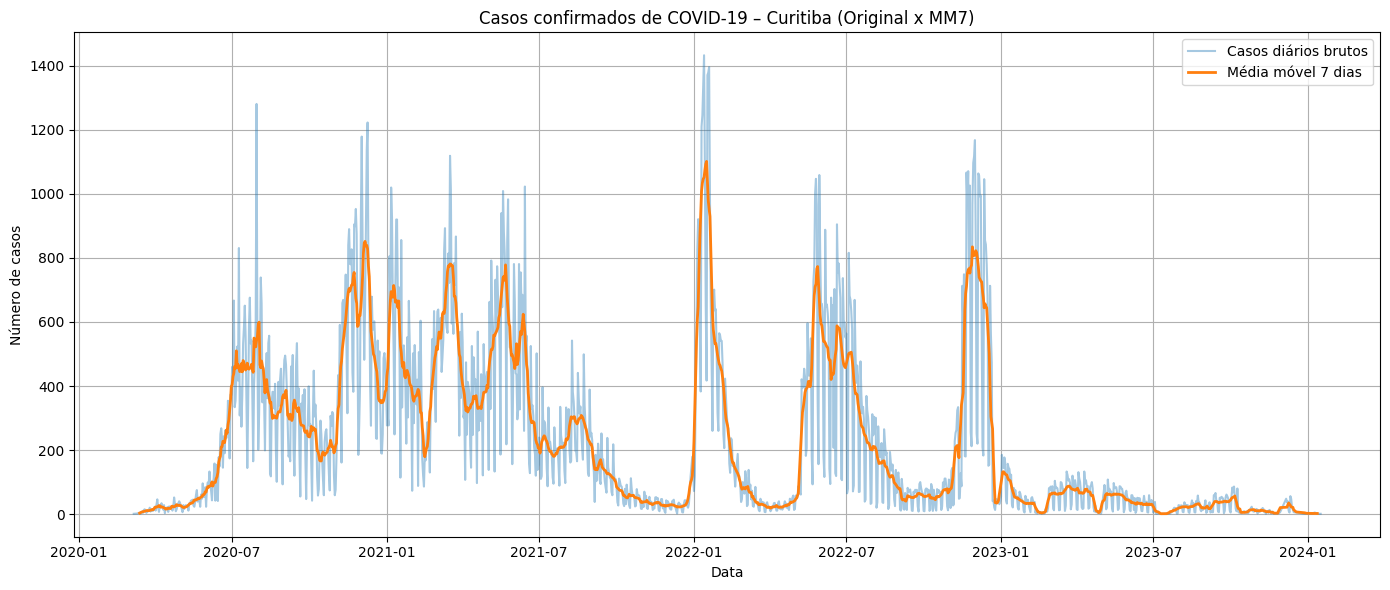

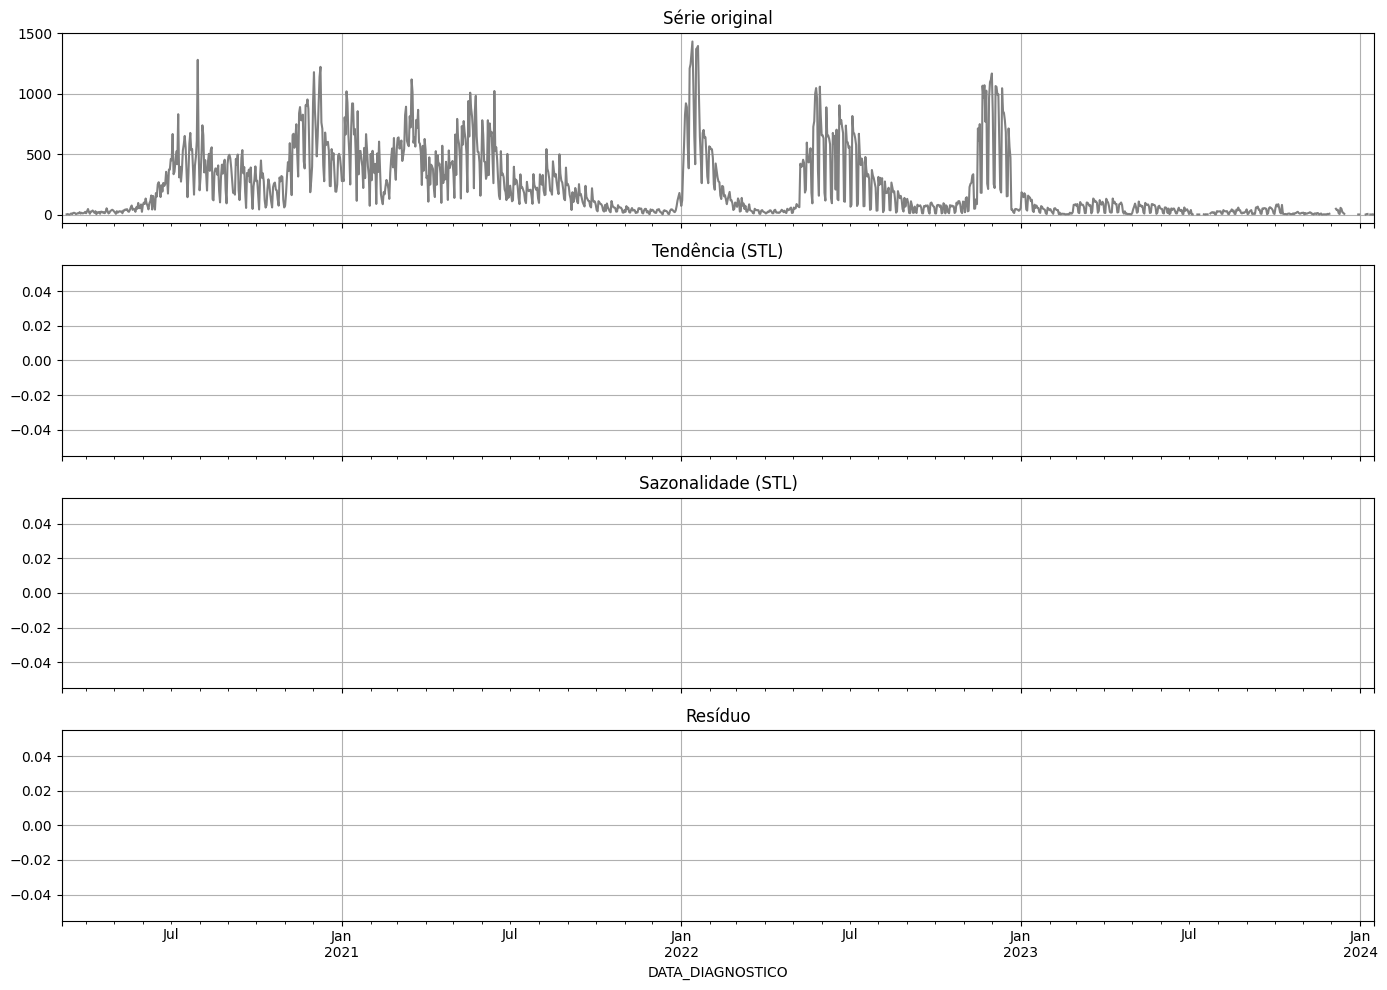

In [1]:
# 1. Importar bibliotecas essenciais
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL       # <-- novo import

# 2. Carregar o arquivo CSV
caminho_arquivo = '../data/raw/casos_covid_parana_raw.csv'
df = pd.read_csv(caminho_arquivo, sep=';', encoding='latin1')

# 3. Filtro e pré-processamento de Curitiba
df_curitiba = df[df['MUN_RESIDENCIA'].str.upper() == 'CURITIBA'].copy()
df_curitiba['DATA_DIAGNOSTICO'] = pd.to_datetime(df_curitiba['DATA_DIAGNOSTICO'],
                                                 errors='coerce')

casos_por_dia = df_curitiba.groupby('DATA_DIAGNOSTICO').size()

# 4. SUAVIZAÇÃO 1 – Média móvel de 7 dias
casos_mm7 = casos_por_dia.rolling(window=7, center=True).mean()

# Gráfico comparando série bruta x média móvel
plt.figure(figsize=(14, 6))
plt.plot(casos_por_dia, label='Casos diários brutos', alpha=0.4)
plt.plot(casos_mm7,   label='Média móvel 7 dias', linewidth=2)
plt.title('Casos confirmados de COVID-19 – Curitiba (Original x MM7)')
plt.xlabel('Data')
plt.ylabel('Número de casos')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 5. SUAVIZAÇÃO 2 – STL Decomposition
# Força frequência diária para o STL
casos_stl = casos_por_dia.asfreq('D')

stl = STL(casos_stl, period=7, robust=True)
resultado = stl.fit()

tendencia  = resultado.trend
sazonal    = resultado.seasonal
residuo    = resultado.resid

# Plotar componentes
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
casos_stl.plot(ax=axes[0], color='gray', label='Original')
axes[0].set_title('Série original'); axes[0].grid(True)

tendencia.plot(ax=axes[1], color='blue', label='Tendência')
axes[1].set_title('Tendência (STL)'); axes[1].grid(True)

sazonal.plot(ax=axes[2], color='green', label='Sazonalidade semanal')
axes[2].set_title('Sazonalidade (STL)'); axes[2].grid(True)

residuo.plot(ax=axes[3], color='red', label='Resíduo')
axes[3].set_title('Resíduo'); axes[3].grid(True)

plt.tight_layout()
plt.show()


# 6. (Opcional) Exportar componentes para análise posterior
componentes = pd.concat([tendencia, sazonal, residuo], axis=1)
componentes.columns = ['tendencia', 'sazonal', 'residuo']
# Decomposição STL: exploratória, não utilizada no TCC (guardada em archive/)
componentes.to_csv('../archive/componentes_stl_curitiba.csv', index=True)


In [2]:
import pandas as pd

# O caminho do seu arquivo
caminho = '../data/raw/casos_covid_parana_raw.csv'

# Carregar apenas 2 colunas para não estourar a memória
print("Lendo o arquivo gigante de forma otimizada...")
df_leve = pd.read_csv(caminho, sep=';', encoding='latin1', usecols=['MUN_RESIDENCIA', 'DATA_DIAGNOSTICO'])

# 1. Total Bruto
print("1. Total bruto SESA:", len(df_leve))

# 2. Filtrar Curitiba (Fazer isso como texto é instantâneo)
df_cwb = df_leve[df_leve['MUN_RESIDENCIA'].str.upper() == 'CURITIBA'].copy()
print("2. Total Curitiba:", len(df_cwb))

# 3. Converter data APENAS para Curitiba (Agora são poucos dados, não trava!)
df_cwb['DATA_DIAGNOSTICO'] = pd.to_datetime(df_cwb['DATA_DIAGNOSTICO'], errors='coerce')

# 4. Filtrar o período de 2020 a 2022
df_final = df_cwb[(df_cwb['DATA_DIAGNOSTICO'] >= '2020-01-01') & (df_cwb['DATA_DIAGNOSTICO'] <= '2022-12-31')]
print("3. Total Curitiba (2020-2022):", len(df_final))

Lendo o arquivo gigante de forma otimizada...


1. Total bruto SESA: 2983763


2. Total Curitiba: 312681
3. Total Curitiba (2020-2022): 299992


## Figuras 2 e 3 do TCC e base intermediária

O código original que gerou as imagens das Figuras 2 e 3 inseridas no TCC não foi localizado (a célula acima gera um gráfico MM7 com outro título). As células abaixo recriam as duas figuras com os mesmos dados, títulos e legendas das versões do TCC e salvam a série diária intermediária.

Dias: 1368 | Total de casos: 312681


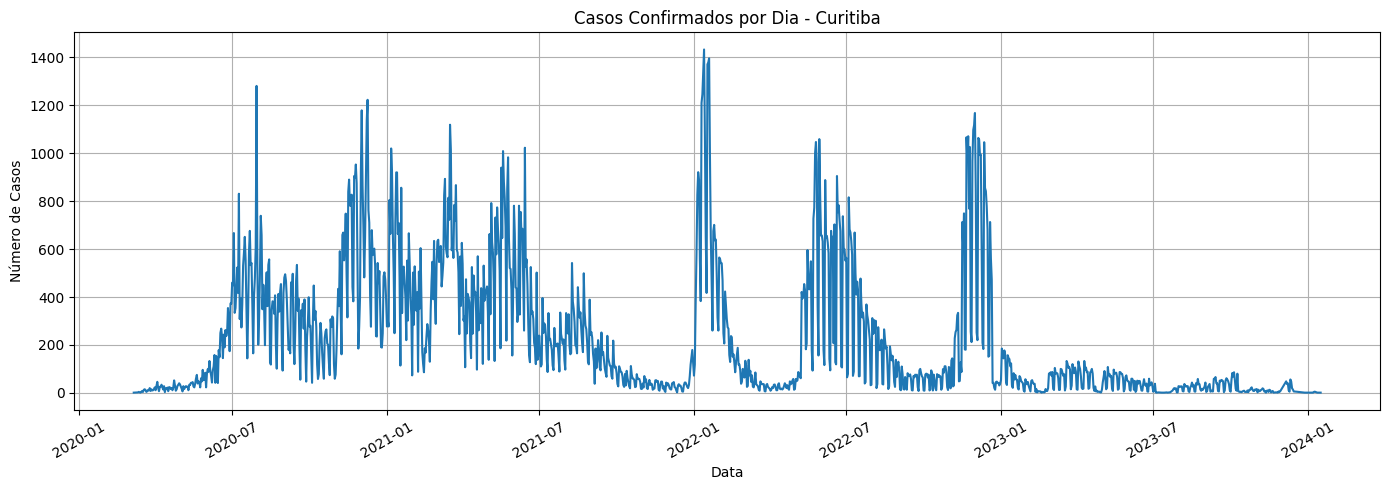

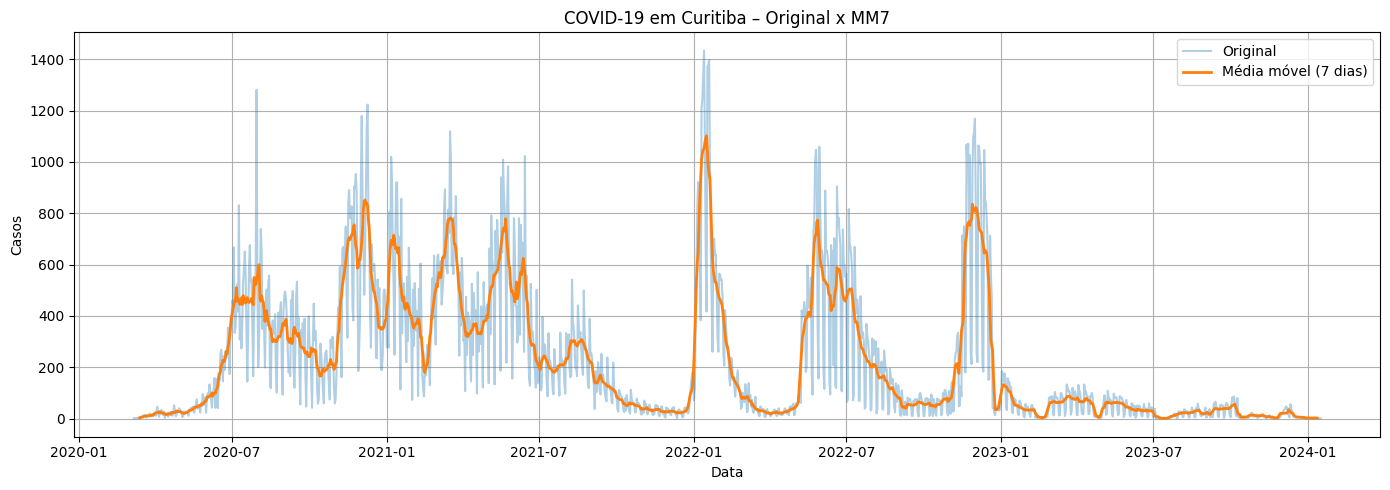

In [3]:
import os
os.makedirs('../data/intermediate', exist_ok=True)
os.makedirs('../results/figures', exist_ok=True)

# Base intermediária: casos confirmados por dia em Curitiba (todo o período disponível)
casos_por_dia.rename('casos_covid').rename_axis('data_diagnostico').to_csv('../data/intermediate/casos_diarios_curitiba.csv')
print('Dias:', len(casos_por_dia), '| Total de casos:', int(casos_por_dia.sum()))

# FIGURA 2 – Casos confirmados por dia em Curitiba (dados brutos)
plt.figure(figsize=(14, 5))
plt.plot(casos_por_dia.index, casos_por_dia.values)
plt.title('Casos Confirmados por Dia - Curitiba')
plt.xlabel('Data')
plt.ylabel('Número de Casos')
plt.grid(True)
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('../results/figures/figura2_casos_diarios_brutos.png', dpi=300, bbox_inches='tight')
plt.show()

# FIGURA 3 – Série original versus média móvel de 7 dias (MM7, centrada)
plt.figure(figsize=(14, 5))
plt.plot(casos_por_dia.index, casos_por_dia.values, alpha=0.35, label='Original')
plt.plot(casos_mm7.index, casos_mm7.values, linewidth=2, label='Média móvel (7 dias)')
plt.title('COVID-19 em Curitiba – Original x MM7')
plt.xlabel('Data')
plt.ylabel('Casos')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('../results/figures/figura3_serie_original_vs_mm7.png', dpi=300, bbox_inches='tight')
plt.show()